# Classificação de Corujas — V4 com base inteira e pesos intermediários

Esta versão usa **toda a base de treino** — sem cortar imagens — mas ajusta os pesos das classes para um ponto intermediário entre a V2 e a V3.

## O que muda

- O treino usa a **tabela inteira**: 5.646 imagens, sem limite por classe.
- Os pesos não são nem a raiz quadrada pura da V2, nem o peso balanceado completo da V3.
- Fórmula adotada:

\[
w_c = 	ext{clip}\left(\left(rac{N}{K \cdot n_c}
ight)^{0.75},\ 0.15,\ 3.0
ight)
\]

- Depois, os pesos são normalizados para que a média ponderada pela quantidade de imagens seja 1.
- O teto de 3,0 evita o comportamento da V3, que chegou a peso 7,69 e gerou muitos falsos positivos.
- O melhor modelo é escolhido por **F1 macro na validação**.
- O `ReduceLROnPlateau` monitora o F1 macro.
- **Nada é salvo no Google Drive.** Métricas, gráficos e o modelo ficam apenas na sessão do Colab.

## Linha de base

| Métrica no teste | V2 | V3 |
|---|---:|---:|
| Acurácia | 60,03% | 31,46% |
| Acurácia balanceada | 13,38% | 20,67% |
| Precisão macro | 14,13% | 12,52% |
| Recall macro | 13,38% | 20,67% |
| F1 macro | 12,66% | 11,74% |
| Classes com recall zero | 12 | 6 |

A V2 usou a base inteira, mas pesos fracos. A V3 usou pesos fortes, mas removeu metade do treino e derrubou a precisão. A V4 tenta ficar entre as duas.


## 1. Bibliotecas e configuração

O TensorFlow já vem instalado no Colab. O notebook não monta o Drive e não salva arquivos externos.


In [ ]:
%pip install -q numpy pandas matplotlib scikit-learn gdown

import sys
import time
import zipfile
from pathlib import Path

import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import callbacks, layers, models

SEMENTE = 42
TAMANHO_IMAGEM = (224, 224)
TAMANHO_LOTE = 32
ALPHA_PESO = 0.75
PESO_MAXIMO = 3.0
PESO_MINIMO = 0.15
EPOCAS = 50

tf.keras.utils.set_random_seed(SEMENTE)

print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
print('Scikit-learn:', sklearn.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))


Python: 3.13.16
TensorFlow: 2.21.0
Scikit-learn: 1.6.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Base de dados

A base é baixada para `/content/imgs` apenas se ainda não existir. Nenhum artefato é enviado ao Drive.


Downloading...
From (original): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is
From (redirected): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is&confirm=t&uuid=be2bcd2e-ee9f-4907-974a-279b50437b8b
To: /content/imgs.zip
100%|██████████| 985M/985M [00:12<00:00, 80.5MB/s]


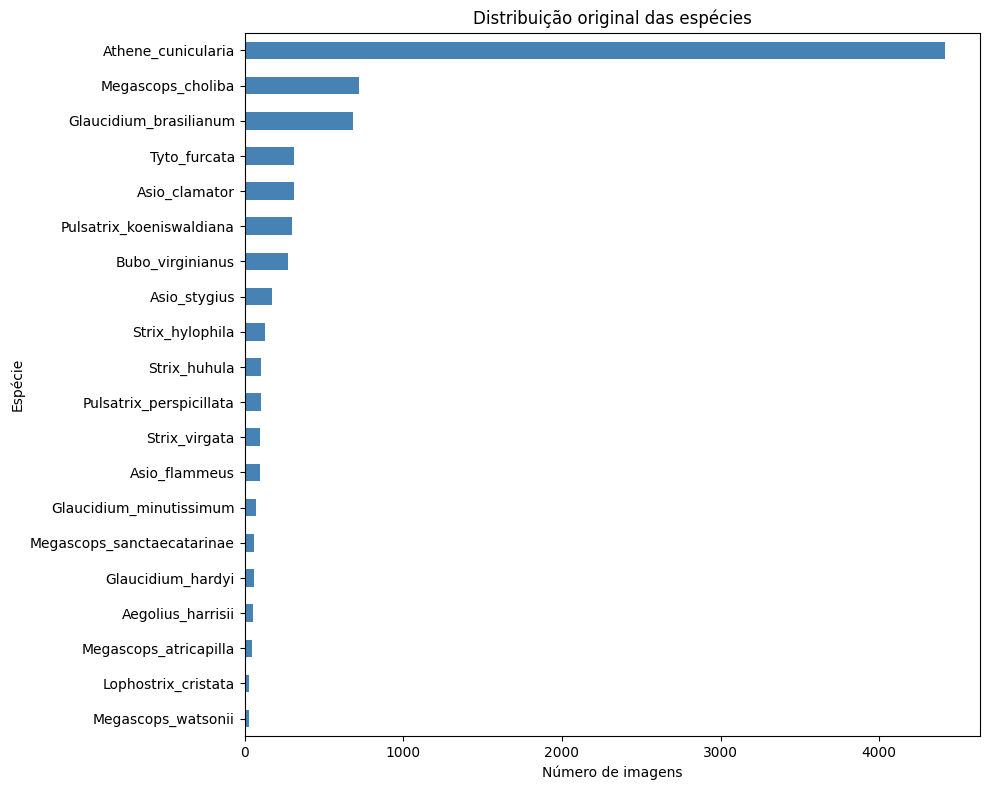

Classes: 20
Total de imagens: 8067
Megascops_watsonii              26
Lophostrix_cristata             27
Megascops_atricapilla           44
Aegolius_harrisii               55
Glaucidium_hardyi               57
Megascops_sanctaecatarinae      58
Glaucidium_minutissimum         74
Asio_flammeus                   96
Strix_virgata                   96
Pulsatrix_perspicillata        105
Strix_huhula                   106
Strix_hylophila                131
Asio_stygius                   175
Bubo_virginianus               271
Pulsatrix_koeniswaldiana       300
Asio_clamator                  310
Tyto_furcata                   312
Glaucidium_brasilianum         686
Megascops_choliba              723
Athene_cunicularia            4415


In [ ]:
FILE_ID = '1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is'
DATA_DIR = Path('/content/imgs')
ZIP_PATH = Path('/content/imgs.zip')

if not DATA_DIR.is_dir():
    url = f'https://drive.google.com/uc?id={FILE_ID}'
    gdown.download(url, output=str(ZIP_PATH), quiet=False)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('/content')
    ZIP_PATH.unlink(missing_ok=True)

if not DATA_DIR.is_dir() and Path('/content/images').is_dir():
    Path('/content/images').rename(DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Diretório não encontrado: {DATA_DIR}')

EXTENSOES_IMAGEM = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
nomes_das_classes = sorted(
    p.name for p in DATA_DIR.iterdir()
    if p.is_dir() and not p.name.startswith(('.', '__'))
)

contagem = {
    classe: sum(
        p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
        for p in (DATA_DIR / classe).iterdir()
    )
    for classe in nomes_das_classes
}

if len(nomes_das_classes) != 20:
    raise ValueError(f'Esperava 20 classes, encontrei {len(nomes_das_classes)}')
if min(contagem.values()) < 2:
    raise ValueError(f'Classes com menos de 2 imagens: {contagem}')

contagem_serie = pd.Series(contagem, dtype='int64').sort_values()
contagem_serie.plot.barh(figsize=(10, 8), color='steelblue')
plt.title('Distribuição original das espécies')
plt.xlabel('Número de imagens')
plt.ylabel('Espécie')
plt.tight_layout()
plt.show()

print('Classes:', len(nomes_das_classes))
print('Total de imagens:', int(contagem_serie.sum()))
print(contagem_serie.to_string())


## 3. Divisão e definição dos pesos

A divisão é a mesma da V2 e da V3: **70% treino, 15% validação e 15% teste**, estratificada e com semente 42. O teste é exatamente o mesmo, então a comparação entre as três versões é direta.

Aqui **não há corte de imagens**. Todas as 5.646 imagens de treino são usadas.

Os pesos são calculados em três passos:

1. peso balanceado: \(w_c = N / (K \cdot n_c)\);
2. suavização intermediária: \(w_c^{0.75}\);
3. limitação em \([0.15, 3.0]\) e normalização para média ponderada 1.

O expoente 0,75 fica entre a V2 (0,5) e a V3 (1,0). O teto de 3,0 impede que as classes com 18–40 imagens recebam peso 7–8, como aconteceu na V3.


**Nota metodológica:** a escolha de `alpha = 0,75` e do teto 3,0 foi motivada pelo comportamento observado nas versões anteriores. Para uma avaliação rigorosa, esse ajuste deveria ser feito usando apenas a validação; o teste deve continuar reservado para a comparação final.

In [ ]:
caminhos = []
rotulos = []
for indice, classe in enumerate(nomes_das_classes):
    arquivos = sorted(
        p for p in (DATA_DIR / classe).iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
    )
    caminhos.extend(str(p) for p in arquivos)
    rotulos.extend([indice] * len(arquivos))

caminhos = np.asarray(caminhos)
rotulos = np.asarray(rotulos, dtype=np.int32)
num_classes = len(nomes_das_classes)

caminhos_treino, caminhos_temp, rotulos_treino, rotulos_temp = train_test_split(
    caminhos, rotulos, test_size=0.30, random_state=SEMENTE, stratify=rotulos
)
caminhos_validacao, caminhos_teste, rotulos_validacao, rotulos_teste = train_test_split(
    caminhos_temp, rotulos_temp, test_size=0.50, random_state=SEMENTE, stratify=rotulos_temp
)

AUTOTUNE = tf.data.AUTOTUNE

def carregar_imagem(caminho, rotulo):
    bytes_imagem = tf.io.read_file(caminho)
    imagem = tf.io.decode_image(bytes_imagem, channels=3, expand_animations=False)
    imagem = tf.image.resize(imagem, TAMANHO_IMAGEM, antialias=True)
    imagem.set_shape((*TAMANHO_IMAGEM, 3))
    return imagem, rotulo

def criar_dataset(caminhos_conjunto, rotulos_conjunto, treinamento=False):
    ds = tf.data.Dataset.from_tensor_slices((caminhos_conjunto, rotulos_conjunto))
    ds = ds.map(carregar_imagem, num_parallel_calls=AUTOTUNE)
    if treinamento:
        ds = ds.shuffle(
            buffer_size=min(len(caminhos_conjunto), 4096),
            seed=SEMENTE,
            reshuffle_each_iteration=True,
        )
    return ds.batch(TAMANHO_LOTE).prefetch(AUTOTUNE)

dataset_treino = criar_dataset(caminhos_treino, rotulos_treino, treinamento=True)
dataset_validacao = criar_dataset(caminhos_validacao, rotulos_validacao)
dataset_teste = criar_dataset(caminhos_teste, rotulos_teste)

print('Treino:', len(caminhos_treino))
print('Validação:', len(caminhos_validacao))
print('Teste:', len(caminhos_teste))

contagem_treino = np.bincount(rotulos_treino, minlength=num_classes)
N = int(contagem_treino.sum())
K = num_classes

# Pesos intermediários entre a V2 (sqrt) e a V3 (balanceado completo).
pesos_balanceados = N / (K * contagem_treino)
pesos_brutos = pesos_balanceados ** ALPHA_PESO
pesos_limitados = np.clip(pesos_brutos, PESO_MINIMO, PESO_MAXIMO)
media_ponderada = np.average(pesos_limitados, weights=contagem_treino)
pesos = pesos_limitados / media_ponderada
pesos_das_classes = {int(i): float(w) for i, w in enumerate(pesos)}

tabela_pesos = pd.DataFrame({
    'Classe': nomes_das_classes,
    'Treino': contagem_treino,
    'Peso balanceado': pesos_balanceados,
    'Peso final': pesos,
}).sort_values('Peso final', ascending=False)
display(tabela_pesos.round(3))

print('Menor peso:', round(float(pesos.min()), 3))
print('Maior peso:', round(float(pesos.max()), 3))
print('Média ponderada dos pesos:', round(float(np.average(pesos, weights=contagem_treino)), 4))
print('Razão maior/menor:', round(float(pesos.max() / pesos.min()), 2))


Treino: 5646
Validação: 1210
Teste: 1211


,Classe,Treino,Peso balanceado,Peso final
0,Aegolius_harrisii,39,7.238,4.063
9,Lophostrix_cristata,19,14.858,4.063
10,Megascops_atricapilla,31,9.106,4.063
7,Glaucidium_hardyi,40,7.058,4.063
13,Megascops_watsonii,18,15.683,4.063
12,Megascops_sanctaecatarinae,41,6.885,4.063
8,Glaucidium_minutissimum,52,5.429,4.063
2,Asio_flammeus,67,4.213,3.983
18,Strix_virgata,67,4.213,3.983
15,Pulsatrix_perspicillata,73,3.867,3.735


Menor peso: 0.225
Maior peso: 4.063
Média ponderada dos pesos: 1.0
Razão maior/menor: 18.05


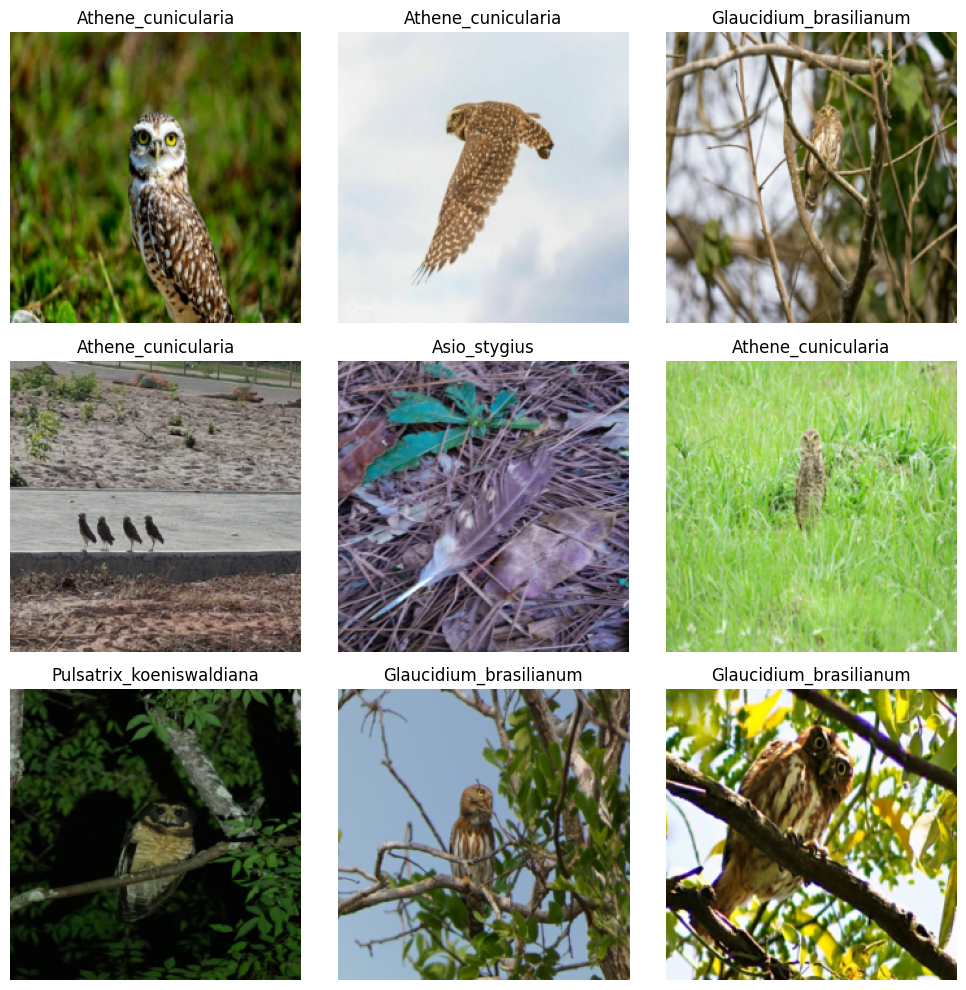

In [ ]:
plt.figure(figsize=(10, 10))
for imagens, rotulos_lote in dataset_treino.take(1):
    for i in range(min(9, len(imagens))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype('uint8'))
        plt.title(nomes_das_classes[int(rotulos_lote[i])])
        plt.axis('off')
plt.tight_layout()
plt.show()


## 4. Arquitetura própria

A arquitetura é a mesma família da v2, mas com dropout menor para combater o subajuste:

- 4 blocos convolucionais;
- 2 convoluções 3×3 por bloco;
- filtros 32 → 64 → 128 → 256;
- BatchNorm;
- MaxPooling;
- Dropout de 0,10 a 0,25;
- GlobalAveragePooling;
- Dense 128;
- Dropout final 0,30;
- Softmax de 20 classes.


In [ ]:
def criar_cnn(num_classes):
    entradas = layers.Input(shape=(*TAMANHO_IMAGEM, 3), name='imagem')

    x = layers.RandomFlip('horizontal')(entradas)
    x = layers.RandomRotation(0.08, fill_mode='reflect')(x)
    x = layers.RandomZoom(0.10, fill_mode='reflect')(x)
    x = layers.RandomContrast(0.10)(x)
    x = layers.Rescaling(1.0 / 255.0, name='normalizacao')(x)

    for filtros, dropout in [(32, 0.10), (64, 0.15), (128, 0.20), (256, 0.25)]:
        for _ in range(2):
            x = layers.Conv2D(
                filtros, 3, padding='same', use_bias=False,
                kernel_initializer='he_normal'
            )(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(dropout)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.30)(x)
    saidas = layers.Dense(num_classes, activation='softmax', name='especie')(x)
    return models.Model(entradas, saidas, name='cnn_corujas_v3')


modelo = criar_cnn(num_classes)
modelo.summary()


Model: "cnn_corujas_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             

 Total params: 1,210,612 (4.62 MB)

 Trainable params: 1,208,692 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 5. Treinamento

A seleção do melhor modelo é feita por **F1 macro na validação**. O `ReduceLROnPlateau` também monitora essa métrica, para não reduzir a taxa de aprendizado enquanto o F1 ainda estiver melhorando.

Nenhum checkpoint é salvo em disco: o `EarlyStopping` restaura os melhores pesos na memória.


In [ ]:
class MetricasValidacao(callbacks.Callback):
    def __init__(self, dataset, rotulos):
        super().__init__()
        self.dataset = dataset
        self.rotulos = np.asarray(rotulos)
        self.f1_hist = []
        self.balanced_hist = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        probabilidades = self.model.predict(self.dataset, verbose=0)
        previstos = np.argmax(probabilidades, axis=1)
        f1 = float(f1_score(self.rotulos, previstos, average='macro', zero_division=0))
        bal = float(balanced_accuracy_score(self.rotulos, previstos))
        logs['val_f1_macro'] = f1
        logs['val_balanced_accuracy'] = bal
        self.f1_hist.append(f1)
        self.balanced_hist.append(bal)


modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

cb_metricas = MetricasValidacao(dataset_validacao, rotulos_validacao)
inicio_treino = time.perf_counter()
history = modelo.fit(
    dataset_treino,
    validation_data=dataset_validacao,
    epochs=EPOCAS,
    class_weight=pesos_das_classes,
    callbacks=[
        cb_metricas,
        callbacks.EarlyStopping(
            monitor='val_f1_macro',
            mode='max',
            patience=8,
            restore_best_weights=True,
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_f1_macro',
            mode='max',
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1,
        ),
    ],
    verbose=2,
)
tempo_treino = time.perf_counter() - inicio_treino

melhor_epoca = int(np.argmax(cb_metricas.f1_hist) + 1)
melhor_f1 = float(max(cb_metricas.f1_hist))
print('Tempo de treino: %.1f s' % tempo_treino)
print('Melhor época:', melhor_epoca)
print('Melhor F1 macro de validação: %.4f' % melhor_f1)


Epoch 1/50
177/177 - 62s - 352ms/step - accuracy: 0.4113 - loss: 2.7696 - val_accuracy: 0.5000 - val_loss: 1.9176 - val_f1_macro: 0.0763 - val_balanced_accuracy: 0.1067 - learning_rate: 0.0010
Epoch 2/50
177/177 - 38s - 214ms/step - accuracy: 0.4547 - loss: 2.6462 - val_accuracy: 0.3884 - val_loss: 1.9753 - val_f1_macro: 0.0724 - val_balanced_accuracy: 0.1003 - learning_rate: 0.0010
Epoch 3/50
177/177 - 38s - 215ms/step - accuracy: 0.4481 - loss: 2.6109 - val_accuracy: 0.5231 - val_loss: 1.8572 - val_f1_macro: 0.0815 - val_balanced_accuracy: 0.1037 - learning_rate: 0.0010
Epoch 4/50
177/177 - 38s - 215ms/step - accuracy: 0.4950 - loss: 2.5840 - val_accuracy: 0.5190 - val_loss: 1.9101 - val_f1_macro: 0.0774 - val_balanced_accuracy: 0.1213 - learning_rate: 0.0010
Epoch 5/50
177/177 - 38s - 215ms/step - accuracy: 0.4860 - loss: 2.5433 - val_accuracy: 0.3116 - val_loss: 2.2072 - val_f1_macro: 0.0593 - val_balanced_accuracy: 0.1128 - learning_rate: 0.0010
Epoch 6/50
177/177 - 38s - 215ms/st

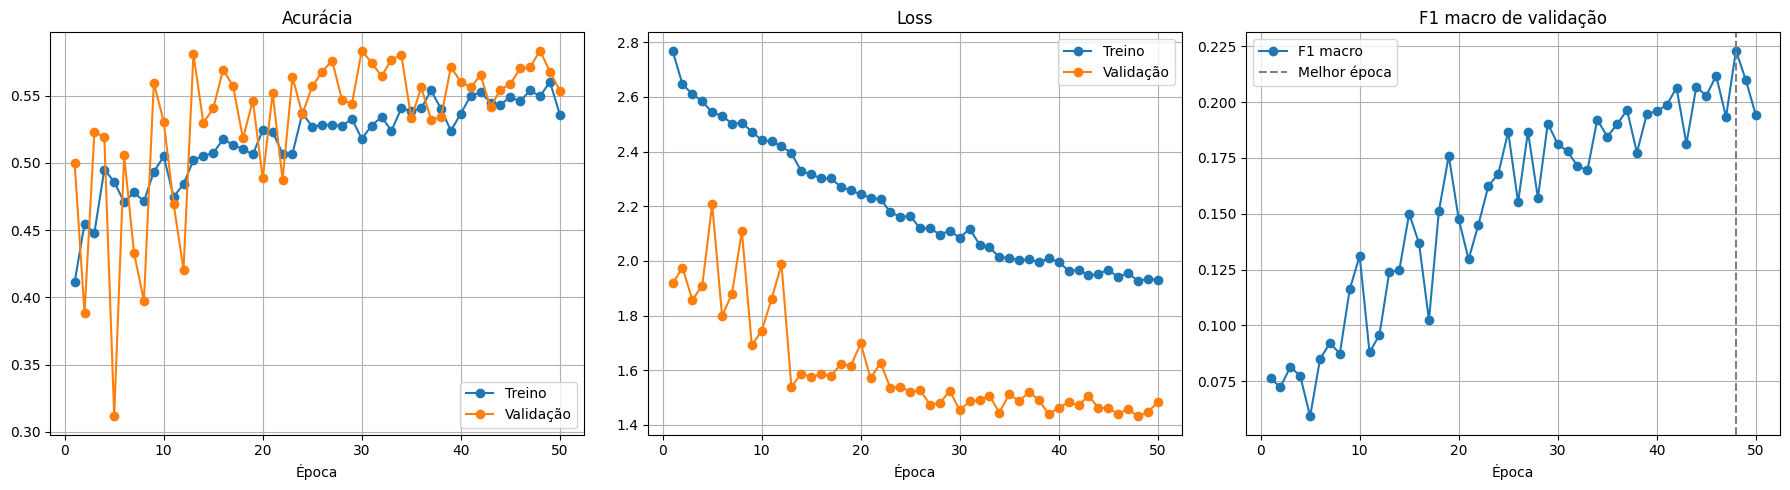

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epocas = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epocas, acc, label='Treino', marker='o')
axes[0].plot(epocas, val_acc, label='Validação', marker='o')
axes[0].set_title('Acurácia')
axes[0].set_xlabel('Época')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epocas, loss, label='Treino', marker='o')
axes[1].plot(epocas, val_loss, label='Validação', marker='o')
axes[1].set_title('Loss')
axes[1].set_xlabel('Época')
axes[1].legend()
axes[1].grid(True)

axes[2].plot(range(1, len(cb_metricas.f1_hist) + 1), cb_metricas.f1_hist, label='F1 macro', marker='o')
axes[2].axvline(melhor_epoca, color='gray', linestyle='--', label='Melhor época')
axes[2].set_title('F1 macro de validação')
axes[2].set_xlabel('Época')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()


## 6. Avaliação no teste

O teste é o mesmo da V2 e da V3. A expectativa é:

- recuperar parte da acurácia perdida na V3, porque a base inteira volta a ser usada;
- manter um recall melhor que o da V2 nas classes raras;
- evitar o colapso de precisão da V3.

A comparação principal deve ser feita em **F1 macro**, **acurácia balanceada** e **recall por espécie**. A acurácia global sozinha não conta a história.


loss_teste: 1.4374
acuracia_teste: 0.5863
acuracia_balanceada: 0.2578
precisao_macro: 0.2382
recall_macro: 0.2578
f1_macro: 0.2282

Relatório por espécie:
                            precision    recall  f1-score   support

         Aegolius_harrisii      0.400     0.250     0.308         8
             Asio_clamator      0.200     0.255     0.224        47
             Asio_flammeus      0.143     0.429     0.214        14
              Asio_stygius      0.154     0.148     0.151        27
        Athene_cunicularia      0.828     0.852     0.840       663
          Bubo_virginianus      0.240     0.439     0.310        41
    Glaucidium_brasilianum      0.571     0.388     0.462       103
         Glaucidium_hardyi      0.000     0.000     0.000         8
   Glaucidium_minutissimum      0.125     0.273     0.171        11
       Lophostrix_cristata      0.000     0.000     0.000         4
     Megascops_atricapilla      0.222     0.333     0.267         6
         Megascops_choliba  

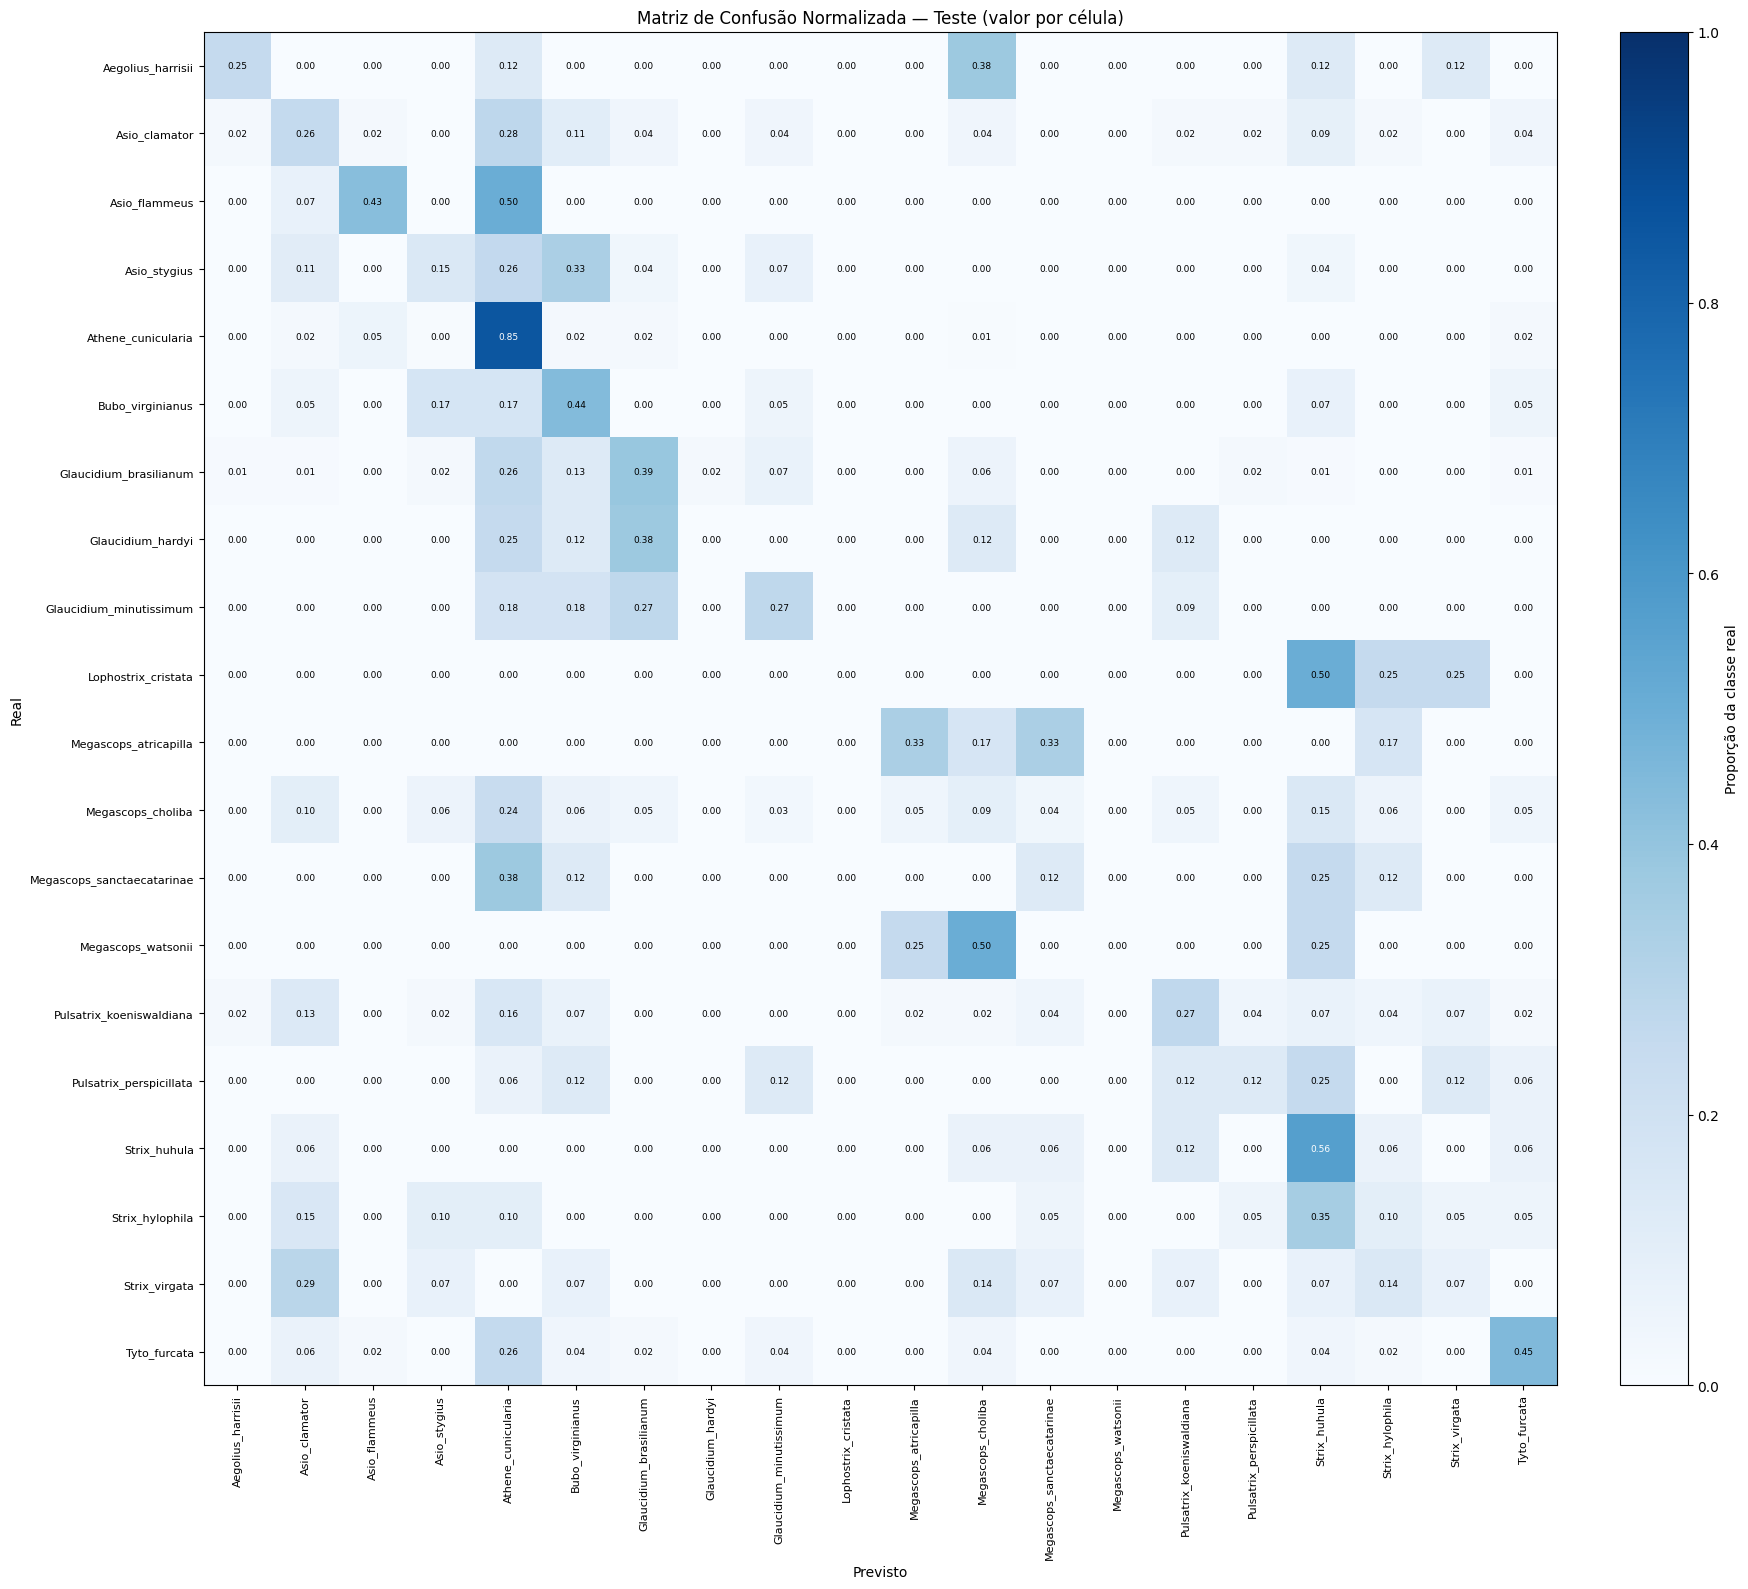

In [ ]:
perda_teste, acuracia_keras = modelo.evaluate(dataset_teste, verbose=0)
probabilidades = modelo.predict(dataset_teste, verbose=0)
y_reais = np.asarray(rotulos_teste)
y_previstos = np.argmax(probabilidades, axis=1)

metricas = {
    'loss_teste': float(perda_teste),
    'acuracia_teste': float(accuracy_score(y_reais, y_previstos)),
    'acuracia_balanceada': float(balanced_accuracy_score(y_reais, y_previstos)),
    'precisao_macro': float(precision_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'recall_macro': float(recall_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'f1_macro': float(f1_score(y_reais, y_previstos, average='macro', zero_division=0)),
}

for nome, valor in metricas.items():
    print(f'{nome}: {valor:.4f}')

print('\nRelatório por espécie:')
print(classification_report(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    target_names=nomes_das_classes,
    digits=3,
    zero_division=0,
))

cm = confusion_matrix(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    normalize='true',
)

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(nomes_das_classes, rotation=90, fontsize=8)
ax.set_yticklabels(nomes_das_classes, fontsize=8)
ax.set_xlabel('Previsto')
ax.set_ylabel('Real')
ax.set_title('Matriz de Confusão Normalizada — Teste (valor por célula)')

for i in range(num_classes):
    for j in range(num_classes):
        valor = cm[i, j]
        ax.text(
            j, i, f'{valor:.2f}',
            ha='center', va='center', fontsize=6.5,
            color='white' if valor > 0.55 else 'black'
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Proporção da classe real')
plt.tight_layout()
plt.show()


,Classe,Suporte no teste,Recall
7,Glaucidium_hardyi,8,0.000
9,Lophostrix_cristata,4,0.000
13,Megascops_watsonii,4,0.000
18,Strix_virgata,14,0.071
11,Megascops_choliba,109,0.092
17,Strix_hylophila,20,0.100
12,Megascops_sanctaecatarinae,8,0.125
15,Pulsatrix_perspicillata,16,0.125
3,Asio_stygius,27,0.148
0,Aegolius_harrisii,8,0.250


Classes com recall zero: ['Glaucidium_hardyi', 'Lophostrix_cristata', 'Megascops_watsonii']
Classes com recall < 10%: ['Glaucidium_hardyi', 'Lophostrix_cristata', 'Megascops_watsonii', 'Strix_virgata', 'Megascops_choliba']


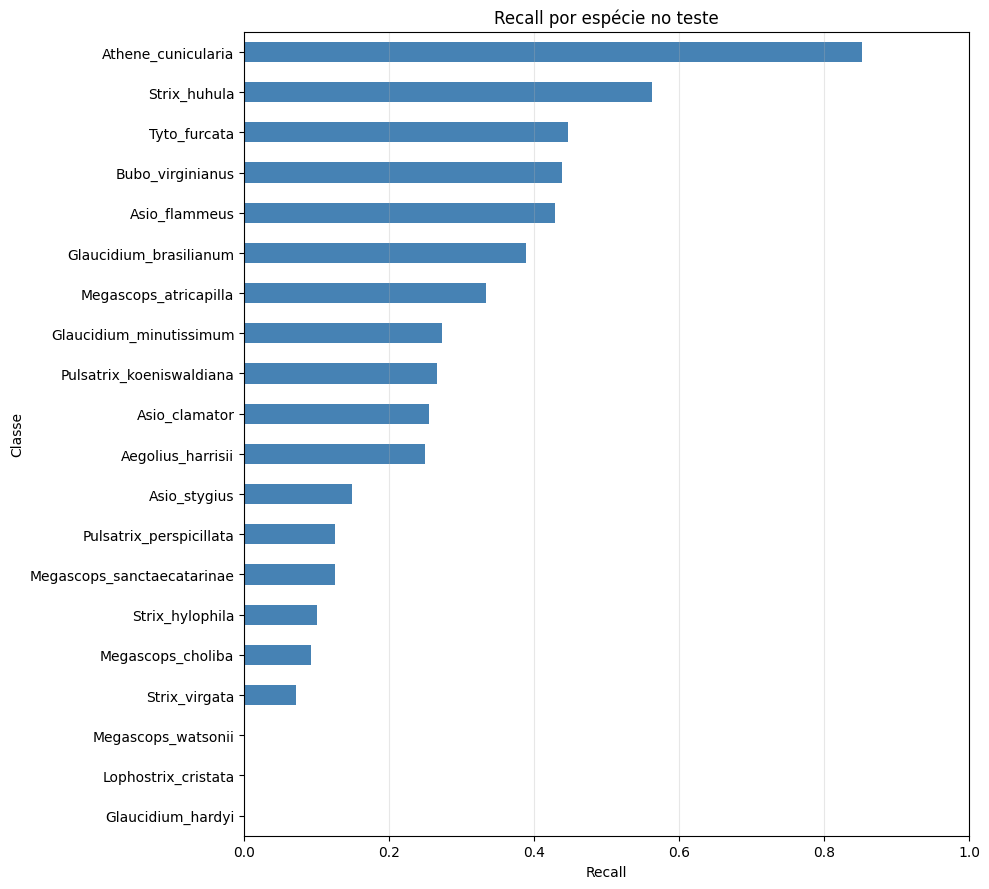

In [ ]:
recall_classes = recall_score(
    y_reais, y_previstos, labels=np.arange(num_classes),
    average=None, zero_division=0
)
suporte = np.bincount(y_reais, minlength=num_classes)

tabela_recall = pd.DataFrame({
    'Classe': nomes_das_classes,
    'Suporte no teste': suporte,
    'Recall': recall_classes,
}).sort_values('Recall')

display(tabela_recall.round(3))

sem_recall = tabela_recall.loc[tabela_recall['Recall'] == 0, 'Classe'].tolist()
baixo_recall = tabela_recall.loc[tabela_recall['Recall'] < 0.10, 'Classe'].tolist()

print('Classes com recall zero:', sem_recall if sem_recall else 'nenhuma')
print('Classes com recall < 10%:', baixo_recall if baixo_recall else 'nenhuma')

tabela_recall.set_index('Classe')['Recall'].plot.barh(
    figsize=(10, 9), color='steelblue'
)
plt.title('Recall por espécie no teste')
plt.xlabel('Recall')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Comparação consolidada

A tabela abaixo usa os resultados já registrados da V2 e da V3 e calcula automaticamente os da V4.


,Versão,Acurácia,Acurácia balanceada,Precisão macro,Recall macro,F1 macro,Classes com recall zero
0,V2,0.6003,0.1338,0.1413,0.1338,0.1266,12
1,V3,0.3146,0.2067,0.1252,0.2067,0.1174,6
2,V4,0.5863,0.2578,0.2382,0.2578,0.2282,3


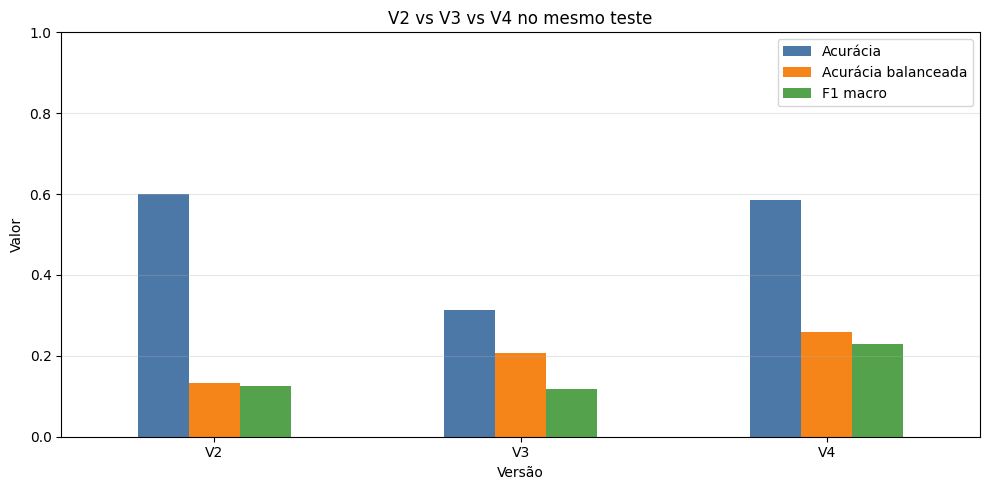

In [ ]:
classes_zero_v4 = int((tabela_recall['Recall'] == 0).sum())

comparativo = pd.DataFrame([
    {
        'Versão': 'V2',
        'Acurácia': 0.6003,
        'Acurácia balanceada': 0.1338,
        'Precisão macro': 0.1413,
        'Recall macro': 0.1338,
        'F1 macro': 0.1266,
        'Classes com recall zero': 12,
    },
    {
        'Versão': 'V3',
        'Acurácia': 0.3146,
        'Acurácia balanceada': 0.2067,
        'Precisão macro': 0.1252,
        'Recall macro': 0.2067,
        'F1 macro': 0.1174,
        'Classes com recall zero': 6,
    },
    {
        'Versão': 'V4',
        'Acurácia': metricas['acuracia_teste'],
        'Acurácia balanceada': metricas['acuracia_balanceada'],
        'Precisão macro': metricas['precisao_macro'],
        'Recall macro': metricas['recall_macro'],
        'F1 macro': metricas['f1_macro'],
        'Classes com recall zero': classes_zero_v4,
    },
])

display(comparativo.round(4))

comparativo.set_index('Versão')[['Acurácia', 'Acurácia balanceada', 'F1 macro']].plot(
    kind='bar', figsize=(10, 5), rot=0,
    color=['#4C78A8', '#F58518', '#54A24B']
)
plt.title('V2 vs V3 vs V4 no mesmo teste')
plt.ylim(0, 1)
plt.ylabel('Valor')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Demonstração dentro do Colab

O modelo permanece na memória da sessão. Não há salvamento no Drive. A célula abaixo permite enviar uma imagem e ver o top-3.


In [2]:
from google.colab import files
from PIL import Image, ImageOps
from IPython.display import display
import numpy as np

# Esta célula é autossuficiente: não depende de TAMANHO_IMAGEM das células anteriores.
TAMANHO_PREVISAO = (224, 224)

if 'modelo' not in globals():
    raise RuntimeError(
        'O modelo não está na memória desta sessão. '
        'Execute as células de treino antes da demonstração.'
    )
if 'nomes_das_classes' not in globals():
    raise RuntimeError(
        'A lista de classes não está na memória desta sessão. '
        'Execute a célula que carrega os nomes das classes antes da demonstração.'
    )

def prever(caminho):
    imagem = ImageOps.exif_transpose(Image.open(caminho)).convert('RGB')
    imagem = imagem.resize(TAMANHO_PREVISAO, Image.Resampling.BILINEAR)
    x = np.asarray(imagem, dtype=np.float32)
    # O modelo já contém o pré-processamento. Não aplique preprocess_input aqui.
    probs = modelo.predict(x[None, ...], verbose=0)[0]
    ordem = np.argsort(probs)[-3:][::-1]
    return [(nomes_das_classes[i], float(probs[i])) for i in ordem]

enviados = files.upload()

if not enviados:
    print('Nenhuma imagem foi enviada.')
else:
    for nome in enviados:
        display(Image.open(nome).convert('RGB'))
        print(f'Imagem: {nome}')
        resultados = prever(nome)
        for classe, prob in resultados:
            print(f'  {classe}: {prob:.2%}')
        if resultados[0][1] < 0.5:
            print('  Aviso: confiança baixa; a imagem pode não ser uma das 20 espécies.')


RuntimeError: O modelo não está na memória desta sessão. Execute as células de treino antes da demonstração.

## 9. Conclusão

A V4 testa uma hipótese mais controlada:

> Com a base inteira e um peso intermediário, é possível manter a acurácia da V2 e melhorar o recall das classes raras sem o colapso de precisão da V3?

O que observar:

1. **F1 macro** deve ser maior que o da V2 e o da V3.
2. **Acurácia balanceada** deve ficar acima da V2.
3. **Recall das classes raras** deve ficar entre o da V2 e o da V3.
4. **Precisão macro** não deve cair como na V3.
5. **Acurácia global** deve se recuperar em relação à V3.

Se o F1 macro continuar baixo, o gargalo não é apenas o peso das classes: é a quantidade de dados e a dificuldade visual das espécies.

Nada foi salvo no Drive. Se a sessão do Colab for encerrada, o modelo e os resultados em memória serão perdidos.
